# Shots and bounces

Cuts on one clip. The filtered track is smoothed, mapped through the ground-plane homography onto the court, and the velocity change is measured there, in meters per second. A pixel of motion near the camera is then the same size of event as the same motion at the far baseline.

A red line on the plot is one detected shot. A blue line is one detected bounce. The frame name is written on the line. Dots are the dataset labels, drawn for comparison; they are not extra cuts.

Edit the thresholds and run from that cell down. `GAME` and `CLIP` default to the clip that contains the calibration frame in `trajectories/game1_landmarks.yaml`. The fit that uses these cuts is `fit_flight.ipynb`.


In [1]:
import csv
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
from tracking.efficient.model import EfficientTracker
from tracking.ssm.base_akf.model import rts_smooth
from trajectories.ballistic import FPS
from trajectories.camera import court_from_image, estimate_homography
from trajectories.court import load_landmarks, marked
from trajectories.segment import detect_cuts, iter_flights, kinematics, velocity_shift

LANDMARKS = ROOT / "trajectories" / "game1_landmarks.yaml"
with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    dataset = (ROOT / dataset).resolve()

# None follows the calibration frame. Set both to open some other clip.
GAME = None
CLIP = None

MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}


In [2]:
_, meta = load_landmarks(LANDMARKS)
rel = Path(meta["frame"])
game = GAME or rel.parts[0]
clip = CLIP or rel.parts[1]


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = dataset / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "status": int(row["status"] or 0),
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    out_w, out_h = tracker.out_w, tracker.out_h
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def read_bgr(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)
    if image.shape[1] != SRC_W or image.shape[0] != SRC_H:
        image = cv2.resize(image, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return image


tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
tracker.rules.start_at_uncertainty = True

frames = load_clip(game, clip)
grays = [read_gray(frame["path"]) for frame in frames]
rgbs = [read_rgb(frame["path"]) for frame in frames]
steps = tracker.find_positions(grays, rgbs)

n = len(frames)
post = np.full((n, 2), np.nan)
meas = np.full((n, 2), np.nan)
state = np.full((n, 4), np.nan)
cov = np.zeros((n, 4, 4))
pred_state = np.full((n, 4), np.nan)
pred_cov = np.zeros((n, 4, 4))
status = np.array([frame["status"] for frame in frames], dtype=np.int64)
for i, step in enumerate(steps):
    if step is None:
        continue
    post[i] = step["post"]
    state[i] = step["state"]
    cov[i] = step["cov"]
    if step["pred_state"] is not None:
        pred_state[i] = step["pred_state"]
        pred_cov[i] = step["pred_cov"]
    if step["used"] and step["z"] is not None:
        meas[i] = step["z"]
print(
    f"{game}/{clip}  {n} frames  "
    f"measured {int(np.isfinite(meas).all(axis=1).sum())}"
)


game1/Clip1  207 frames  measured 184


## Thresholds

The position is the smoothed track mapped onto the court. A rise in court `|Δvy|` through `EVENT_MPS` is an event. The event also has to fall within `X_ZERO_FRAMES` of a court-X velocity within `X_ZERO_MPS` of zero, or of a court-X sign change. The change used to name that event is the median court velocity over `WINDOW` frames before it, against the median over `WINDOW` frames after it.

A court-X change that clears `X_CHANGE_MPS` is a hit. With `REQUIRE_Y_FLIP` on, a court-Y sign change, negative to positive or positive to negative, is a hit too. Set it to `False` to ignore the sign. If neither the X change nor the sign flip happens, the court-Y change decides: `HIT_Y_CHANGE_MPS` is a hit and `BOUNCE_Y_CHANGE_MPS` is a bounce, so the hit cut can sit higher. Court Y points toward the near baseline. Court X points to the right.

`REARM_MPS` is how quiet `|Δvy|` has to get before another event can fire. `MIN_GAP` is the minimum frames between events. A dataset bounce within `MIN_GAP` of a detected bounce replaces it, so the two are not drawn as a pair.


In [3]:
EVENT_MPS = 10.0
HIT_Y_CHANGE_MPS = 50
BOUNCE_Y_CHANGE_MPS = 8.0
X_CHANGE_MPS = 10.0
REQUIRE_Y_FLIP = False
X_ZERO_FRAMES = 4
X_ZERO_MPS = 0.0
WINDOW = 5
REARM_MPS = 6.0
MIN_GAP = 5

landmarks, _ = load_landmarks(LANDMARKS)
ready = marked(landmarks)
world = np.stack([item.world for item in ready])
uv_mark = np.stack([item.image for item in ready])
on_ground = np.abs(world[:, 2]) <= 1e-8
H = estimate_homography(world[on_ground, :2], uv_mark[on_ground])

smooth = rts_smooth(state, cov, pred_state, pred_cov)
smooth_xy = smooth[:, :2]
court = court_from_image(smooth_xy, H)

event_change = EVENT_MPS / FPS
hit_y_change = HIT_Y_CHANGE_MPS / FPS
bounce_y_change = BOUNCE_Y_CHANGE_MPS / FPS
x_change = X_CHANGE_MPS / FPS
rearm_change = REARM_MPS / FPS
shots, bounces = detect_cuts(
    court,
    status,
    event_change=event_change,
    hit_y_change=hit_y_change,
    bounce_y_change=bounce_y_change,
    x_change=x_change,
    require_y_flip=REQUIRE_Y_FLIP,
    x_zero_frames=X_ZERO_FRAMES,
    x_zero=X_ZERO_MPS / FPS,
    window=WINDOW,
    rearm=rearm_change,
    min_gap=MIN_GAP,
)
MATCH_FRAMES = 2

label_hits = [i for i, code in enumerate(status) if int(code) == 1]
label_bounces = [i for i, code in enumerate(status) if int(code) == 2]
flights = iter_flights(n, shots, bounces)
velocity, _ = kinematics(court)
y_delta = np.full(len(velocity), np.nan)
for i in range(1, len(velocity)):
    if np.isfinite(velocity[i, 1]) and np.isfinite(velocity[i - 1, 1]):
        y_delta[i] = abs(velocity[i, 1] - velocity[i - 1, 1])
change_mps = y_delta * FPS


def label_runs(codes):
    """One event per run of the same hit or bounce label."""
    runs = []
    i = 0
    codes = [int(code) for code in codes]
    while i < len(codes):
        code = codes[i]
        if code not in (1, 2):
            i += 1
            continue
        j = i + 1
        while j < len(codes) and codes[j] == code:
            j += 1
        runs.append((i, j - 1, code))
        i = j
    return runs


def run_distance(index, start, end):
    if start <= index <= end:
        return 0
    if index < start:
        return start - index
    return index - end


def run_name(start, end):
    if start == end:
        return frames[start]["file"]
    return f"{frames[start]['file']}–{frames[end]['file']}"


label_events = label_runs(status)
detections = [(index, 1) for index in shots] + [(index, 2) for index in bounces if index not in set(shots)]
used = set()
matches = []
unmatched_labels = []
for start, end, code in label_events:
    options = [
        (run_distance(index, start, end), index)
        for index, kind in detections
        if kind == code and index not in used and run_distance(index, start, end) <= MATCH_FRAMES
    ]
    if not options:
        unmatched_labels.append((start, end, code))
        continue
    _, index = min(options)
    used.add(index)
    matches.append((index, code, start, end))
unmatched_detections = [(index, kind) for index, kind in detections if index not in used]


def report(kind, indices):
    if not indices:
        print(f"{kind:7} none")
        return
    for index in indices:
        label = MOVEMENT.get(int(status[index]), "")
        extra = f"   label {label}" if label != "flying" else ""
        value = change_mps[index]
        shown = f"{value:6.1f} m/s" if np.isfinite(value) else "     —"
        shift = velocity_shift(velocity, index, WINDOW)
        if shift is None:
            windows = ""
        else:
            dx, dy, flip = shift
            windows = f"   Δx {dx * FPS:5.1f}  Δy {dy * FPS:5.1f}  y flip {str(flip):5}"
        print(f"{kind:7} {frames[index]['file']}   frame {index:3d}   |Δvy| {shown}{windows}{extra}")


print("detected, one event per line")
report("shot", shots)
report("bounce", bounces)
print()
print(f"matches, within {MATCH_FRAMES} frames of a label run")
if not matches:
    print("none")
for index, code, start, end in matches:
    kind = "shot" if code == 1 else "bounce"
    name = MOVEMENT[code]
    off = run_distance(index, start, end)
    gap = "same frame" if off == 0 else f"{off} frame off"
    print(f"{kind:7} {frames[index]['file']}   frame {index:3d}   matches {name} {run_name(start, end)}   {gap}")
print()
print("unmatched labels, a run of the same label is one event")
if not unmatched_labels:
    print("none")
for start, end, code in unmatched_labels:
    name = MOVEMENT[code]
    span = f"frame {start:3d}" if start == end else f"frames {start:3d}–{end:<3d}"
    print(f"{name:7} {run_name(start, end)}   {span}")
print()
print("unmatched detections")
if not unmatched_detections:
    print("none")
for index, code in unmatched_detections:
    kind = "shot" if code == 1 else "bounce"
    print(f"{kind:7} {frames[index]['file']}   frame {index:3d}")
print()
for i, flight in enumerate(flights):
    segment = meas[flight.start : flight.end + 1]
    count = int(np.isfinite(segment).all(axis=1).sum())
    print(
        f"{i:2d}  {frames[flight.start]['file']} → {frames[flight.end]['file']}"
        f"  measured {count:3d}  ends on bounce: {flight.ends_on_bounce}"
    )


detected, one event per line
shot    0026.jpg   frame  26   |Δvy|   27.6 m/s   Δx  18.0  Δy  37.0  y flip True    label hit
shot    0041.jpg   frame  41   |Δvy|   14.4 m/s   Δx  15.6  Δy  55.4  y flip False   label hit
shot    0084.jpg   frame  84   |Δvy|   10.5 m/s   Δx  12.7  Δy  36.0  y flip False
shot    0115.jpg   frame 115   |Δvy|   11.2 m/s   Δx  10.6  Δy  67.7  y flip True    label hit
shot    0141.jpg   frame 141   |Δvy|   38.1 m/s   Δx   1.9  Δy  76.6  y flip True    label hit
shot    0174.jpg   frame 174   |Δvy|   18.6 m/s   Δx   9.9  Δy  54.4  y flip True 
bounce  0033.jpg   frame  33   |Δvy|    8.2 m/s   Δx   6.5  Δy  39.4  y flip False   label bouncing
bounce  0074.jpg   frame  74   |Δvy|   12.9 m/s   Δx   3.3  Δy  28.8  y flip False
bounce  0105.jpg   frame 105   |Δvy|    4.0 m/s   Δx   1.1  Δy  48.7  y flip True    label bouncing
bounce  0131.jpg   frame 131   |Δvy|   25.6 m/s   Δx   3.5  Δy  44.3  y flip False   label bouncing
bounce  0164.jpg   frame 164   |Δvy|    9.

## The signal

The trace is the court `|Δvy|`, in meters per second. The dashed line is the event threshold. Each vertical line is one cut, and the text on it is the frame. Red is a shot, blue is a bounce. A dot is a dataset label at that frame's change, so a miss sits next to the threshold that rejected it. The middle trace is court-X velocity, to the right. The lower trace is court-Y velocity, toward the near baseline. A shot is an X change, a Y sign flip when `REQUIRE_Y_FLIP` is on, or a Y change that clears the hit cut. A bounce is the case with neither the X change nor the sign flip, and a Y change that clears only the bounce cut.


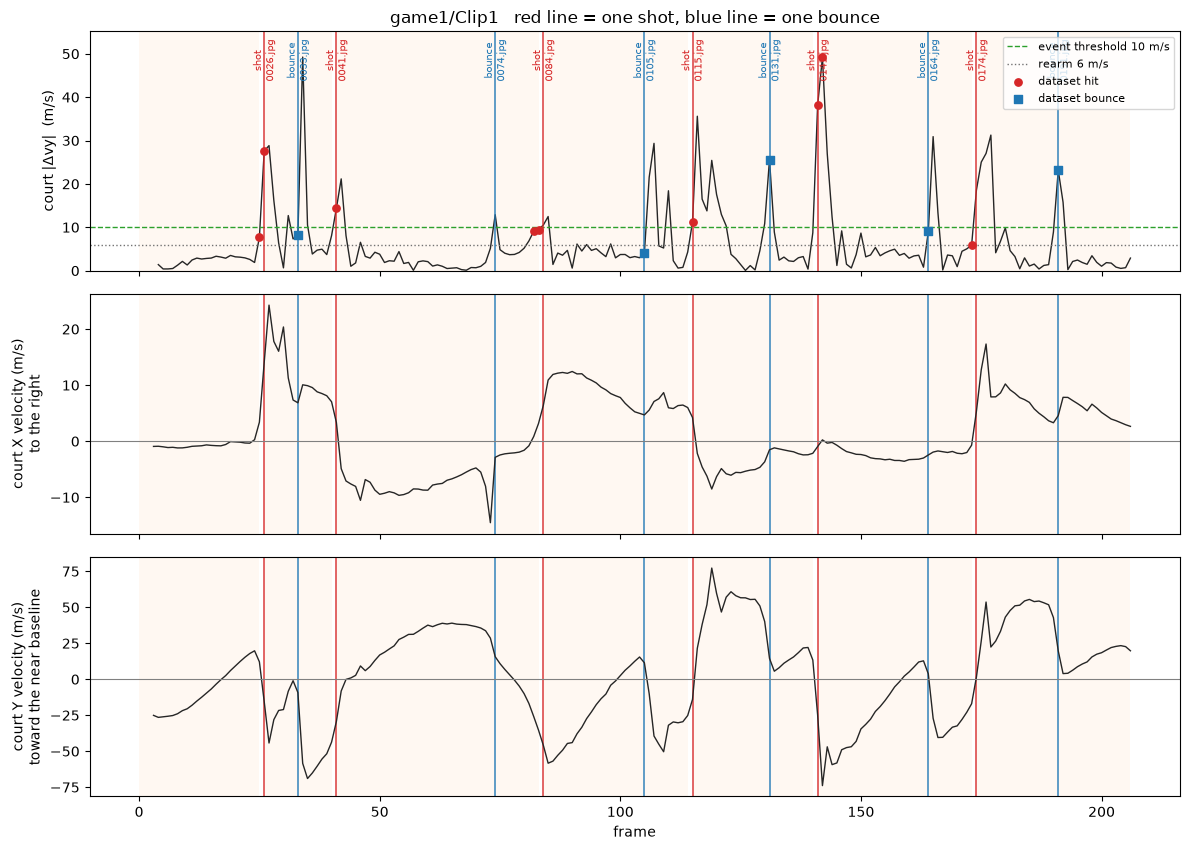

In [4]:
velocity, _ = kinematics(court)
speed_mps = velocity * FPS

fig, axes = plt.subplots(3, 1, figsize=(12, 8.6), sharex=True)
finite = change_mps[np.isfinite(change_mps)]
top = float(np.percentile(finite, 99)) if finite.size else EVENT_MPS
top = max(top, EVENT_MPS * 1.3)

axes[0].plot(change_mps, color="0.15", lw=1)
axes[0].axhline(EVENT_MPS, color="C2", ls="--", lw=1, label=f"event threshold {EVENT_MPS:g} m/s")
axes[0].axhline(REARM_MPS, color="0.45", ls=":", lw=1, label=f"rearm {REARM_MPS:g} m/s")
axes[0].set_ylim(0, top * 1.45)


def mark(indices, color, name):
    for ax in axes:
        for index in indices:
            ax.axvline(index, color=color, lw=1.1, alpha=0.9)
    for index in indices:
        axes[0].text(
            index,
            top * 1.40,
            f"{name}\n{frames[index]['file']}",
            rotation=90,
            va="top",
            ha="center",
            color=color,
            fontsize=7,
            clip_on=False,
        )


mark(shots, "C3", "shot")
mark(bounces, "C0", "bounce")
axes[0].scatter(label_hits, change_mps[label_hits], s=28, c="C3", zorder=3, label="dataset hit")
axes[0].scatter(
    label_bounces, change_mps[label_bounces], s=28, c="C0", marker="s", zorder=3, label="dataset bounce"
)
axes[0].set_ylabel("court |Δvy|  (m/s)")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title(f"{game}/{clip}   red line = one shot, blue line = one bounce")

axes[1].plot(speed_mps[:, 0], color="0.15", lw=1)
axes[1].axhline(0.0, color="0.5", lw=0.8)
axes[1].set_ylabel("court X velocity (m/s)\nto the right")

axes[2].plot(speed_mps[:, 1], color="0.15", lw=1)
axes[2].axhline(0.0, color="0.5", lw=0.8)
axes[2].set_ylabel("court Y velocity (m/s)\ntoward the near baseline")
axes[2].set_xlabel("frame")
for axis in axes:
    for flight in flights:
        axis.axvspan(flight.start, flight.end, color="C1", alpha=0.05, lw=0)
fig.tight_layout()
plt.show()


## One event at a time

Each crop is one event, in frame order. The trail is the smoothed track. A red ring is a shot, a blue ring is a bounce. A detection within `MATCH_FRAMES` of a label run is a match, so that label is not shown again. A missed label is one run of the same label.


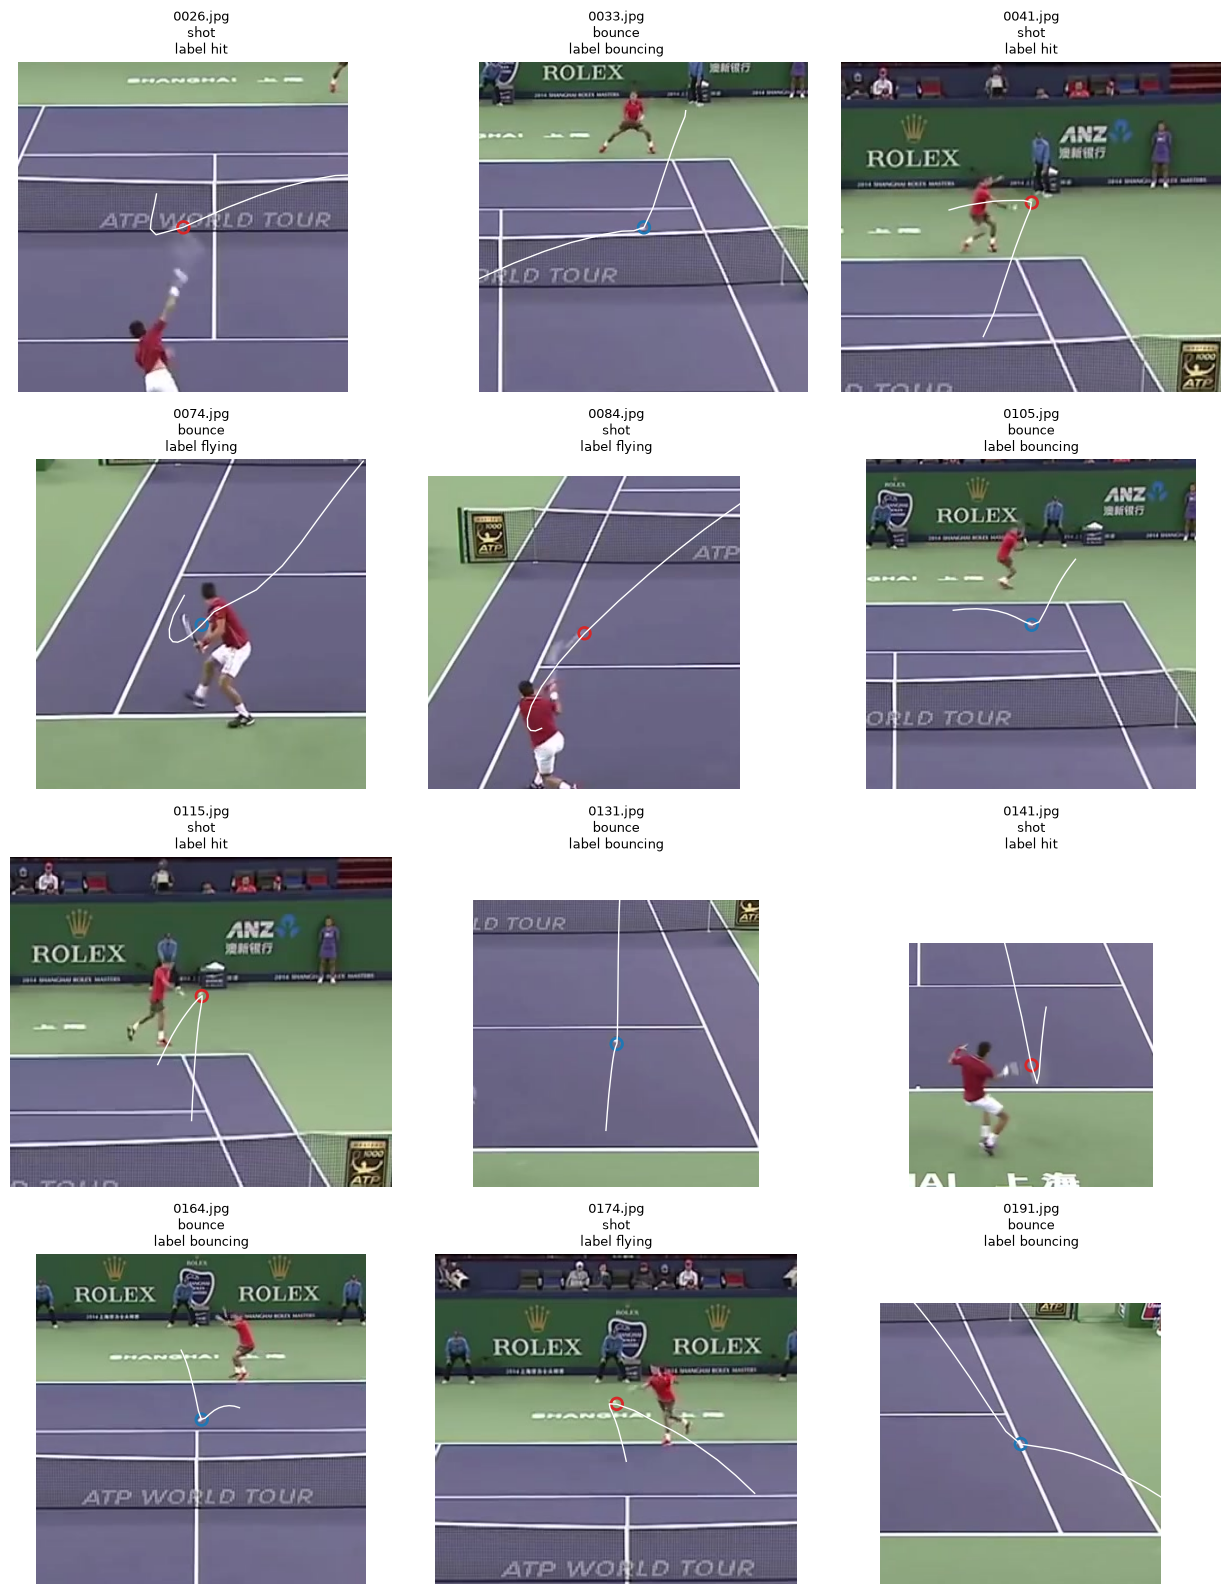

In [12]:
RADIUS = 160
TRAIL = 8

events = [(index, "shot") for index in shots]
events += [(index, "bounce") for index in bounces if index not in set(shots)]
for start, end, code in unmatched_labels:
    events.append((start, "missed hit" if code == 1 else "missed bounce"))
events.sort()

if not events:
    print("no events")
else:
    cols = 3
    rows = int(np.ceil(len(events) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.0 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (index, event) in zip(axes, events):
        point = smooth_xy[index]
        if not np.isfinite(point).all():
            point = post[index]
        image = cv2.cvtColor(read_bgr(frames[index]["path"]), cv2.COLOR_BGR2RGB)
        label = MOVEMENT.get(int(status[index]), str(int(status[index])))
        if not np.isfinite(point).all():
            ax.imshow(image)
            ax.set_title(f"{frames[index]['file']}\n{event}\nlabel {label}", fontsize=9)
            ax.set_axis_off()
            continue
        x, y = int(round(float(point[0]))), int(round(float(point[1])))
        x0, x1 = max(0, x - RADIUS), min(image.shape[1], x + RADIUS)
        y0, y1 = max(0, y - RADIUS), min(image.shape[0], y + RADIUS)
        ax.imshow(image[y0:y1, x0:x1])
        trail_x, trail_y = [], []
        for j in range(max(0, index - TRAIL), min(n, index + TRAIL + 1)):
            if np.isfinite(smooth_xy[j]).all():
                trail_x.append(smooth_xy[j, 0] - x0)
                trail_y.append(smooth_xy[j, 1] - y0)
            else:
                trail_x.append(np.nan)
                trail_y.append(np.nan)
        ax.plot(trail_x, trail_y, color="white", lw=1)
        color = "C3" if "shot" in event or "hit" in event else "C0"
        ax.scatter([x - x0], [y - y0], s=70, facecolors="none", edgecolors=color, linewidths=2)
        ax.set_title(f"{frames[index]['file']}\n{event}\nlabel {label}", fontsize=9)
        ax.set_axis_off()
    for ax in axes[len(events) :]:
        ax.set_axis_off()
    fig.tight_layout()
    plt.show()
